#Import libraries

In [23]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries imported successfully.")

Libraries imported successfully.


#Load the data

In [24]:

main_df = pd.read_csv('model_2_2.csv')
matches = pd.read_csv('matches_clean.csv', parse_dates=['date'])
players = pd.read_csv('players_clean.csv')
team_matches = pd.read_csv('team_matches_clean.csv')

print("main_df shape:", main_df.shape)
print("matches shape:", matches.shape)
print("players shape:", players.shape)
print("team_matches shape:", team_matches.shape)
display(main_df.head(2))

main_df shape: (208, 13)
matches shape: (104, 21)
players shape: (1039, 67)
team_matches shape: (208, 18)


,row_id,match_id,team,opponent,x1_rank_diff,x2_host_advantage,x3_strong_conf_diff,x4_kickoff_hour,x5_attack_form,x6_opp_defence_form,x7_is_knockout,x8_high_altitude,y_goals
0,1,1,Mexico,South Africa,46,1,0,13.0,1.480769,1.480769,0,1,2
1,2,1,South Africa,Mexico,-46,-1,0,13.0,1.480769,1.480769,0,1,0


# Feature engineering for forward vs defender goal contribution difference

In [25]:

players['team'] = players['squad'].str.split(' ', n=1).str[1]

def get_pos_group(pos):
    pos_str = str(pos)
    if 'FW' in pos_str:
        return 'Forward'
    elif 'DF' in pos_str:
        return 'Defender'
    return 'Other'

players['pos_group'] = players['pos'].apply(get_pos_group)

fw_df_contrib = []
for _, tm in team_matches.iterrows():
    t = tm['team']
    match_id = tm['match_id']

    tp = players[players['team'] == t]
    fw = tp[tp['pos_group'] == 'Forward']
    df_pos = tp[tp['pos_group'] == 'Defender']

    fw_ga = (fw['goals'].sum() + fw['assists'].sum()) / max(1, (fw['minutes'].sum() / 90))
    df_ga = (df_pos['goals'].sum() + df_pos['assists'].sum()) / max(1, (df_pos['minutes'].sum() / 90))

    fw_df_contrib.append({
        'match_id': match_id,
        'team': t,
        'fw_df_contrib_diff': fw_ga - df_ga
    })

contrib_df = pd.DataFrame(fw_df_contrib)
merged_df = pd.merge(main_df, contrib_df, on=['match_id', 'team'], how='left')

print("Merged dataset shape:", merged_df.shape)
display(merged_df[['match_id', 'team', 'fw_df_contrib_diff', 'y_goals']].head(5))

Merged dataset shape: (208, 14)


,match_id,team,fw_df_contrib_diff,y_goals
0,1,Mexico,0.624389,2
1,1,South Africa,0.094637,0
2,2,Korea Republic,0.213270,2
3,2,Czechia,-0.223695,1
4,3,Canada,0.650155,1


#Checking the dataset & feature correlation

In [26]:

features = [
    'x1_rank_diff',
    'x2_host_advantage',
    'x3_strong_conf_diff',
    'x4_kickoff_hour',
    'x5_attack_form',
    'x6_opp_defence_form',
    'x7_is_knockout',
    'x8_high_altitude',
    'fw_df_contrib_diff'
]

correlation_results = merged_df[features].corrwith(merged_df['y_goals']).round(2)
print("Correlation with y_goals:")
print(correlation_results)

Correlation with y_goals:
x1_rank_diff           0.46
x2_host_advantage      0.12
x3_strong_conf_diff    0.26
x4_kickoff_hour       -0.02
x5_attack_form         0.10
x6_opp_defence_form    0.20
x7_is_knockout        -0.01
x8_high_altitude      -0.06
fw_df_contrib_diff     0.42
dtype: float64


#Exploratory data analysis

In [27]:

summary_stats = merged_df[features + ['y_goals']].describe().round(2)
display(summary_stats)

,x1_rank_diff,x2_host_advantage,x3_strong_conf_diff,x4_kickoff_hour,x5_attack_form,x6_opp_defence_form,x7_is_knockout,x8_high_altitude,fw_df_contrib_diff,y_goals
count,208.00,208.00,208.00,208.00,208.00,208.00,208.00,208.00,208.00,208.00
mean,0.00,0.00,0.00,16.56,1.63,1.35,0.31,0.09,0.44,1.48
std,35.32,0.38,0.76,3.12,0.61,0.60,0.46,0.28,0.38,1.39
min,-79.00,-1.00,-1.00,12.00,0.49,0.25,0.00,0.00,-0.22,0.00
25%,-25.00,0.00,-1.00,13.00,1.24,0.90,0.00,0.00,0.20,0.00
50%,0.00,0.00,0.00,17.00,1.48,1.24,0.00,0.00,0.40,1.00
75%,25.00,0.00,1.00,19.00,1.90,1.48,1.00,0.00,0.65,2.00
max,79.00,1.00,1.00,22.00,4.24,4.24,1.00,1.00,1.72,7.00


# Exploratory data analysis

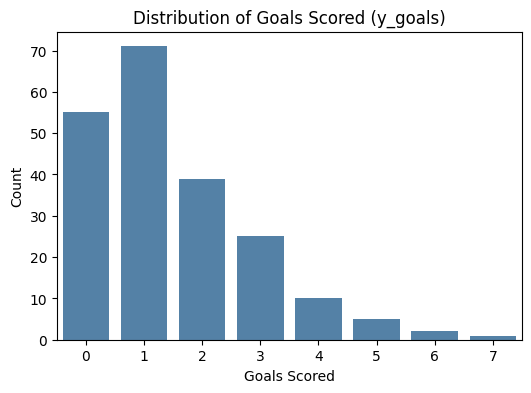

Mean y_goals: 1.48
Std y_goals: 1.39


In [28]:

plt.figure(figsize=(6, 4))
sns.countplot(x='y_goals', data=merged_df, color='steelblue')
plt.title('Distribution of Goals Scored (y_goals)')
plt.xlabel('Goals Scored')
plt.ylabel('Count')
plt.show()

print('Mean y_goals:', round(merged_df['y_goals'].mean(), 2))
print('Std y_goals:', round(merged_df['y_goals'].std(), 2))

# Correlation matrix heatmap

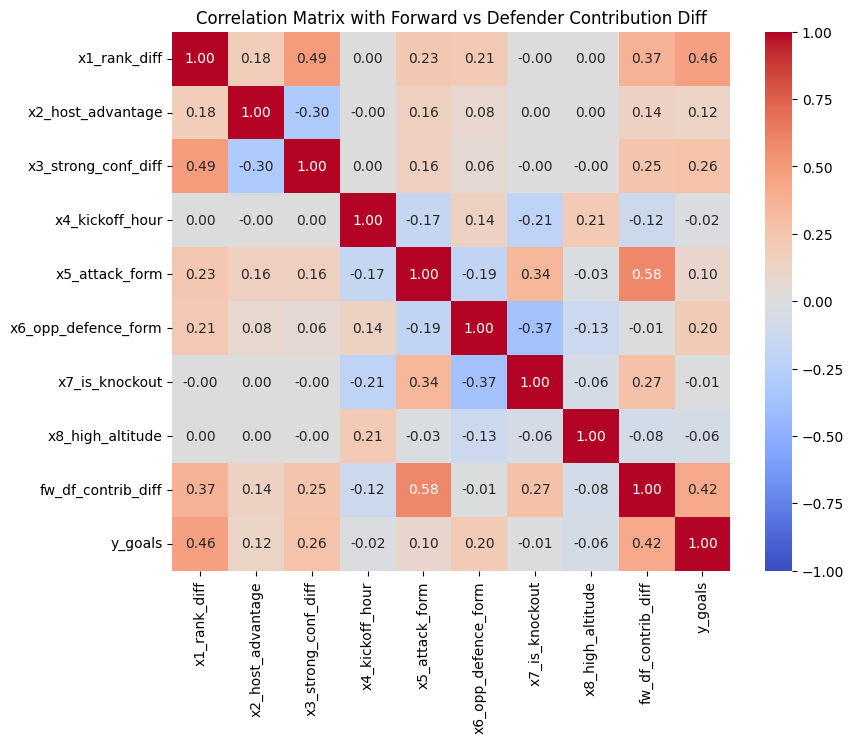

In [29]:

plt.figure(figsize=(9, 7))
sns.heatmap(merged_df[features + ['y_goals']].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix with Forward vs Defender Contribution Diff')
plt.show()

# Feature regression plots

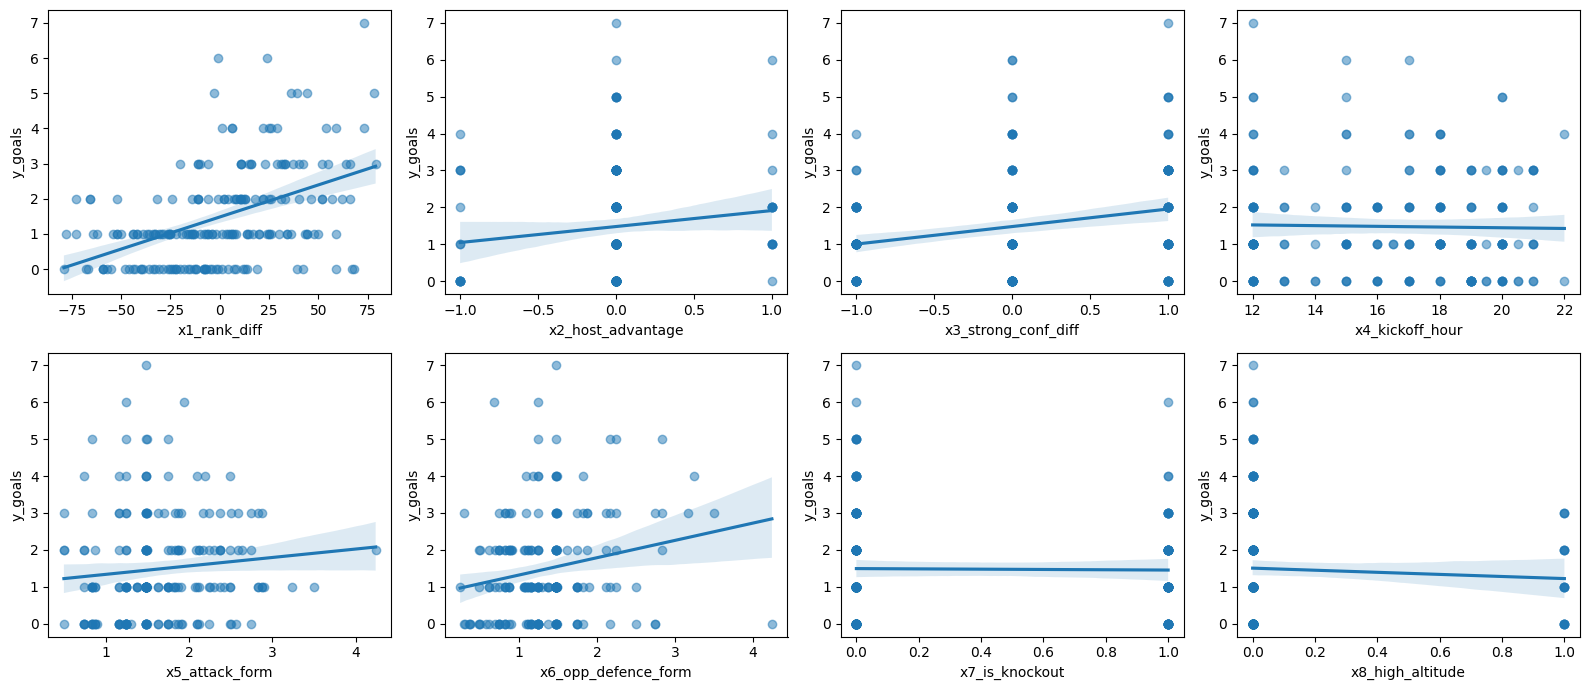

In [33]:

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flat, features):
    sns.regplot(x=col, y='y_goals', data=merged_df, ax=ax, scatter_kws={'alpha': 0.5})
plt.tight_layout()
plt.show()

# Checking multicollinearity

In [30]:

def vif(X_data):
    X_sm = sm.add_constant(X_data)
    return pd.Series(
        [variance_inflation_factor(X_sm.values, i) for i in range(1, X_sm.shape[1])],
        index=X_data.columns
    ).round(2)

X = merged_df[features]
y = merged_df['y_goals']

print("Variance Inflation Factor (VIF):")
print(vif(X))

Variance Inflation Factor (VIF):
x1_rank_diff           1.72
x2_host_advantage      1.36
x3_strong_conf_diff    1.70
x4_kickoff_hour        1.11
x5_attack_form         1.68
x6_opp_defence_form    1.31
x7_is_knockout         1.32
x8_high_altitude       1.09
fw_df_contrib_diff     1.72
dtype: float64


# Linear regression model

In [31]:

X_sm = sm.add_constant(X)
ols_model = sm.OLS(y, X_sm).fit()
print(ols_model.summary())

                            OLS Regression Results                            
Dep. Variable:                y_goals   R-squared:                       0.326
Model:                            OLS   Adj. R-squared:                  0.295
Method:                 Least Squares   F-statistic:                     10.64
Date:                Tue, 13 Oct 2026   Prob (F-statistic):           2.08e-13
Time:                        12:53:43   Log-Likelihood:                -322.61
No. Observations:                 208   AIC:                             665.2
Df Residuals:                     198   BIC:                             698.6
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                   1.4735    

#Cross-validation evaluation

In [32]:

groups = merged_df['match_id']
gkf = GroupKFold(n_splits=10)

cv_preds = cross_val_predict(LinearRegression(), X, y, groups=groups, cv=gkf)

print("--- Cross-Validation Performance Metrics ---")
print(f"MAE: {mean_absolute_error(y, cv_preds):.3f}")
print(f"MSE: {mean_squared_error(y, cv_preds):.3f}")
print(f"R2 Score: {r2_score(y, cv_preds):.3f}")

--- Cross-Validation Performance Metrics ---
MAE: 0.917
MSE: 1.442
R2 Score: 0.254
